# SARD dataset demo

SARD consists of 1920x1080 frames extracted from drone video, with person annotations in COCO format. The copy used here is the Roboflow export from https://universe.roboflow.com/datasets-pdabr/sard-8xjhy (version "ORIGINAL", COCO format), extracted to `../data/sard` with `train`, `valid` and `test` folders.

In [1]:
import json
import os
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageDraw

DATA = '../data/sard'

## Annotation structure

In [2]:
with open(os.path.join(DATA, 'train', '_annotations.coco.json')) as f:
    coco = json.load(f)

print('categories:', [c['name'] for c in coco['categories']])
print('images:', len(coco['images']))
print('annotations:', len(coco['annotations']))

categories: ['person', 'human']
images: 1387
annotations: 4598


## Images per split

In [3]:
def count_jpgs(path):
    return len([n for n in os.listdir(path) if n.endswith('.jpg')])

counts = {s: count_jpgs(os.path.join(DATA, s)) for s in ('train', 'valid', 'test')}
pd.DataFrame({'count': counts})

,count
train,1387
valid,396
test,197


## A sample image with its bounding boxes

In [4]:
by_image = {}
for ann in coco['annotations']:
    by_image.setdefault(ann['image_id'], []).append(ann)

# pick the image with the most annotations
image_id = max(by_image, key=lambda i: len(by_image[i]))
image_info = next(im for im in coco['images'] if im['id'] == image_id)
print(image_info['file_name'], '-', len(by_image[image_id]), 'annotations')

gss1491_jpg.rf.f0c190a7f9a3d948cae12d7120f9a800.jpg - 9 annotations


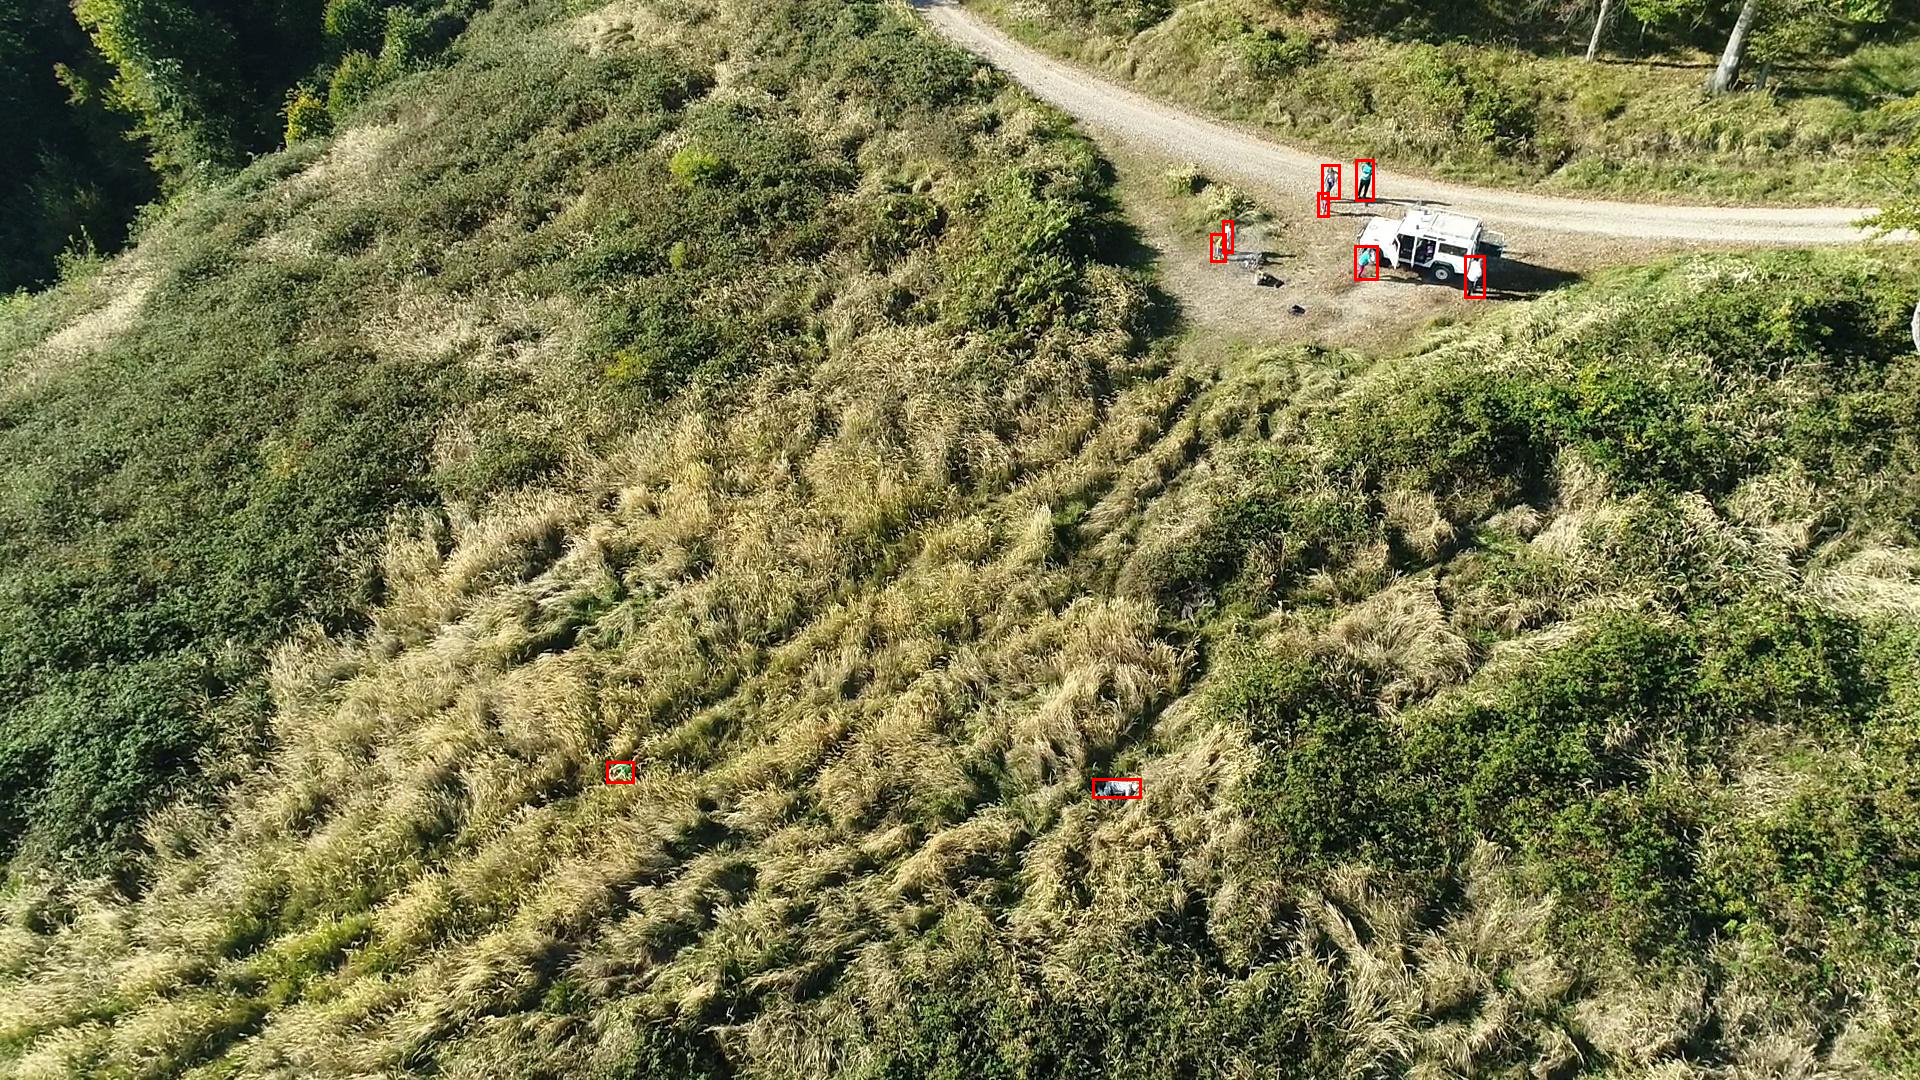

In [5]:
sample = Image.open(os.path.join(DATA, 'train', image_info['file_name']))

annotated = sample.copy()
draw = ImageDraw.Draw(annotated)
for ann in by_image[image_id]:
    x, y, w, h = ann['bbox']
    draw.rectangle([x, y, x + w, y + h], outline='red', width=3)
annotated

## Annotations per image

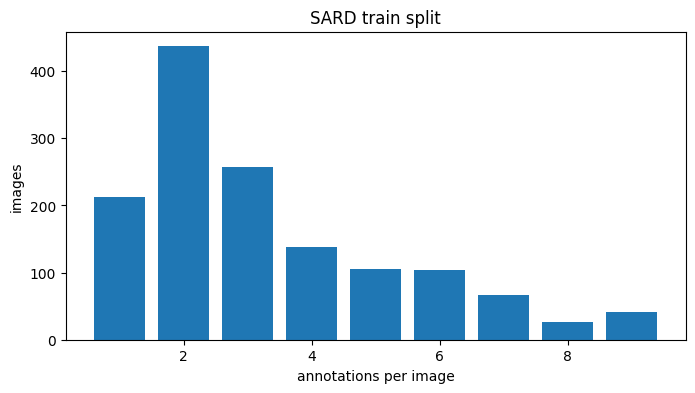

In [6]:
ann_counts = Counter(len(v) for v in by_image.values())
images_without = len(coco['images']) - len(by_image)
if images_without:
    ann_counts[0] = images_without

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(ann_counts.keys(), ann_counts.values())
ax.set_xlabel('annotations per image')
ax.set_ylabel('images')
ax.set_title('SARD train split')
plt.show()

## Check image dimensions for consistency

In [7]:
def check_img_dims(path, expected_dims):
    issue_found = False
    for name in os.listdir(path):
        if not name.endswith('.jpg'):
            continue
        with Image.open(os.path.join(path, name)) as img:
            if img.size != expected_dims:
                issue_found = True
                print(f'expected {expected_dims} but got {img.size} for {name}')
    if not issue_found:
        print(f'all images in {path} are {expected_dims}')

for split in ('train', 'valid', 'test'):
    check_img_dims(os.path.join(DATA, split), (1920, 1080))

all images in ../data/sard\train are (1920, 1080)


all images in ../data/sard\valid are (1920, 1080)


all images in ../data/sard\test are (1920, 1080)


## Use with the training pipeline

The raw COCO layout is not what `IPSARDataset` loads. Run `notebooks/dataset_demo_and_harmonization.ipynb` to convert SARD (together with HERIDAL) into the unified dataset, then `drone_sar/split_unified_dataset.py` to produce the train/val/test folders used by `drone_sar/train.py`.